## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/initial/summary.csv')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261010/summary.csv', '--seed', '20261010', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261010')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261011/summary.csv', '--seed', '20261011', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261011')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/negative_initial/summary.csv', '--polarity', 'negative', '--output-dir', 'logs/spatial_bin_event_propagation/negative_initial')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/negative_seed_20261010/summary.csv', '--polarity', 'negative', '--seed', '20261010', '--output-dir', 'logs/spatial_bin_event_propagation/negative_seed_20261010')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/negative_seed_20261011/summary.csv', '--polarity', 'negative', '--seed', '20261011', '--output-dir', 'logs/spatial_bin_event_propagation/negative_seed_20261011')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/initial/model_summary.csv')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/seed_20261010/model_summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261010/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/seed_20261010')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/seed_20261011/model_summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261011/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/seed_20261011')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/reversed_initial/model_summary.csv', '--reverse-time', '--output-dir', 'logs/spatial_pde_library/reversed_initial')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/reversed_seed_20261010/model_summary.csv', '--reverse-time', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261010/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/reversed_seed_20261010')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/reversed_seed_20261011/model_summary.csv', '--reverse-time', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261011/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/reversed_seed_20261011')


复用： logs/spatial_bin_event_propagation/initial/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261010/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261011/summary.csv
复用： logs/spatial_bin_event_propagation/negative_initial/summary.csv
复用： logs/spatial_bin_event_propagation/negative_seed_20261010/summary.csv
复用： logs/spatial_bin_event_propagation/negative_seed_20261011/summary.csv
复用： logs/spatial_pde_library/initial/model_summary.csv
复用： logs/spatial_pde_library/seed_20261010/model_summary.csv
复用： logs/spatial_pde_library/seed_20261011/model_summary.csv
复用： logs/spatial_pde_library/reversed_initial/model_summary.csv
复用： logs/spatial_pde_library/reversed_seed_20261010/model_summary.csv
复用： logs/spatial_pde_library/reversed_seed_20261011/model_summary.csv


### notebook 内部短计算：audit_raw_source


In [2]:
import json
import subprocess
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
LABELS = {1: 'REM', 2: 'Awake', 3: 'NREM'}

def decode_matlab_string(file: h5py.File, reference: h5py.Reference) -> str:
    codes = file[reference][()].reshape(-1)
    return ''.join((chr(int(code)) for code in codes))

def video_metadata(path: Path) -> dict:
    command = [str(PROJECT_ROOT / 'venv/bin/ffprobe'), '-v', 'error', '-show_entries', 'format=duration,size,start_time:stream=index,codec_name,width,height,r_frame_rate,avg_frame_rate,nb_frames,duration', '-of', 'json', str(path)]
    return json.loads(subprocess.run(command, check=True, capture_output=True, text=True).stdout)


In [3]:
from types import SimpleNamespace

audit_raw_source_sentinel = PROJECT_ROOT / 'logs/audit_raw_source/initial/summary.json'
if FORCE_RECOMPUTE or not audit_raw_source_sentinel.exists():
    args = SimpleNamespace(raw_dir=PROJECT_ROOT / 'data/raw', converted_dir=PROJECT_ROOT / 'data/processed', output_dir=PROJECT_ROOT / 'logs/audit_raw_source/initial', equality_samples=10000, seed=20261009)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    node_info = pd.read_csv(args.converted_dir / 'node_info.csv', index_col=0)
    time_info = pd.read_csv(args.converted_dir / 'time_info.csv', index_col=0)
    converted = np.load(args.converted_dir / 'data.npy', mmap_mode='r')
    with h5py.File(args.raw_dir / 'wholebrain_output_after_rejection.mat', 'r') as file:
        trace = file['whole_trace_ori']
        center = file['whole_center'][()].T
        trace_metadata = {'shape': list(trace.shape), 'dtype': str(trace.dtype), 'chunks': list(trace.chunks), 'compression': trace.compression}
        rng = np.random.default_rng(args.seed)
        time_sample = rng.integers(0, trace.shape[0], size=args.equality_samples)
        node_sample = rng.integers(0, trace.shape[1], size=args.equality_samples)
        raw_sample = np.asarray([trace[int(t), int(n)] for t, n in zip(time_sample, node_sample, strict=True)])
        converted_sample = converted[time_sample, node_sample]
    with h5py.File(args.raw_dir / 'valid_area.mat', 'r') as file:
        acs = np.asarray([decode_matlab_string(file, reference) for reference in file['acs'][:, 0]])
        names = np.asarray([decode_matlab_string(file, reference) for reference in file['names'][:, 0]])
        ids = file['ids'][()].reshape(-1)
        coordinates_2d = file['whole_center_2d_T'][()].T
        ccf = file['CCF'][()]
    with h5py.File(args.raw_dir / 'stimuli.mat', 'r') as file:
        starts = file['stimuli/start_edge'][()].reshape(-1).astype(int) - 1
        stops = file['stimuli/end_edge'][()].reshape(-1).astype(int)
        label_ids = file['stimuli/stimuili_label_ind'][()].reshape(-1).astype(int)
    rebuilt_labels = np.empty(len(time_info), dtype='U8')
    episode_rows = []
    for start, stop, label_id in zip(starts, stops, label_ids, strict=True):
        rebuilt_labels[start:stop] = LABELS[label_id]
        episode_rows.append({'start_zero_based': int(start), 'stop_exclusive': int(stop), 'length': int(stop - start), 'label_id': int(label_id), 'state': LABELS[label_id]})
    pd.DataFrame(episode_rows).to_csv(args.output_dir / 'raw_episodes.csv', index=False)
    geometry = pd.DataFrame({'raw_coord_1': center[:, 0], 'raw_coord_2': center[:, 1], 'raw_coord_3': center[:, 2], 'raw_auxiliary_4_unknown': center[:, 3], 'projected_coord_x': coordinates_2d[:, 0], 'projected_coord_y': coordinates_2d[:, 1], 'acs': acs, 'name': names, 'atlas_id': ids})
    geometry.to_csv(args.output_dir / 'raw_node_geometry.csv', index=False)
    coordinate_correlation = np.corrcoef(np.column_stack([center, coordinates_2d]).T)
    summary = {'source_readme_interpretation': 'whole_trace_ori is described as firing-rate information, but no physical unit or preprocessing method is specified', 'trace': trace_metadata, 'converted_shape': list(converted.shape), 'sampled_value_equality': {'n': args.equality_samples, 'all_exact': bool(np.array_equal(raw_sample, converted_sample)), 'max_absolute_difference': float(np.max(np.abs(raw_sample - converted_sample)))}, 'metadata_exact': {'acs': bool(np.array_equal(acs, node_info['acs'].astype(str).to_numpy())), 'names': bool(np.array_equal(names, node_info['names'].astype(str).to_numpy())), 'ids': bool(np.allclose(ids, node_info['ids'].to_numpy(), equal_nan=True)), 'coordinates_2d': bool(np.allclose(coordinates_2d, node_info[['coords_2d_x', 'coords_2d_y']].to_numpy()))}, 'state_labels_exact': bool(np.array_equal(rebuilt_labels, time_info['stimuli'].astype(str).to_numpy())), 'episodes_contiguous': bool(np.all(starts[1:] == stops[:-1]) and starts[0] == 0 and (stops[-1] == len(time_info))), 'raw_geometry': {'shape': list(center.shape), 'column_min': center.min(axis=0).tolist(), 'column_max': center.max(axis=0).tolist(), 'column_unique_count': [int(len(np.unique(center[:, column]))) for column in range(center.shape[1])], 'correlation_with_projected_xy': coordinate_correlation[:4, 4:].tolist()}, 'ccf_mask': {'shape': list(ccf.shape), 'true_pixels': int(ccf.sum()), 'fraction_true': float(ccf.mean())}, 'video': video_metadata(args.raw_dir / '51.mp4')}
    (args.output_dir / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(summary, ensure_ascii=False, indent=2))
else:
    print('复用：', audit_raw_source_sentinel.relative_to(PROJECT_ROOT))


复用： logs/audit_raw_source/initial/summary.json


### notebook 内部短计算：spatial_scan_axis_diagnostic


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

def median_r2(lags: np.ndarray, coordinates: np.ndarray) -> float:
    coordinates = (coordinates - coordinates.mean(axis=0)) / coordinates.std(axis=0)
    design = np.column_stack([np.ones(len(coordinates)), coordinates])
    values = []
    for target in lags:
        prediction = design @ np.linalg.lstsq(design, target, rcond=None)[0]
        denominator = np.sum((target - target.mean()) ** 2)
        values.append(1.0 - np.sum((target - prediction) ** 2) / denominator if denominator > 0 else 0.0)
    return float(np.median(values))


In [5]:
from types import SimpleNamespace

spatial_scan_axis_diagnostic_sentinel = PROJECT_ROOT / 'logs/spatial_scan_axis_diagnostic/initial/scan_axis_diagnostics.csv'
if FORCE_RECOMPUTE or not spatial_scan_axis_diagnostic_sentinel.exists():
    args = SimpleNamespace(runs_dir=PROJECT_ROOT / 'logs/spatial_bin_event_propagation', raw_geometry=PROJECT_ROOT / 'logs/audit_raw_source/initial/raw_node_geometry.csv', output_dir=PROJECT_ROOT / 'logs/spatial_scan_axis_diagnostic/initial')
    args.output_dir.mkdir(parents=True, exist_ok=True)
    geometry = pd.read_csv(args.raw_geometry)
    rows = []
    for path in sorted(args.runs_dir.glob('*/event_arrays.npz')):
        archive = np.load(path)
        selected, bins, centers = (archive['selected_nodes'], archive['selected_bins'], archive['centers'])
        n_bins = len(centers)
        raw = np.stack([geometry.iloc[selected].groupby(bins)[column].mean().reindex(range(n_bins)).to_numpy() for column in ('raw_coord_1', 'raw_coord_2', 'raw_coord_3', 'raw_auxiliary_4_unknown')], axis=1)
        for state in ('Awake', 'NREM'):
            lags = archive[f'{state}_event_lags_seconds']
            mean_lag = lags.mean(axis=0)
            rows.append({'run': path.parent.name, 'state': state, 'projected_2d_median_r2': median_r2(lags, centers), 'raw_3d_median_r2': median_r2(lags, raw[:, :3]), 'depth_only_median_r2': median_r2(lags, raw[:, 2:3]), 'auxiliary_only_median_r2': median_r2(lags, raw[:, 3:4]), 'mean_lag_depth_correlation': float(np.corrcoef(mean_lag, raw[:, 2])[0, 1]), 'mean_lag_auxiliary_correlation': float(np.corrcoef(mean_lag, raw[:, 3])[0, 1])})
    result = pd.DataFrame(rows)
    result.to_csv(args.output_dir / 'scan_axis_diagnostics.csv', index=False)
    print(result.to_string(index=False))
else:
    print('复用：', spatial_scan_axis_diagnostic_sentinel.relative_to(PROJECT_ROOT))


复用： logs/spatial_scan_axis_diagnostic/initial/scan_axis_diagnostics.csv


# Spatial-direction controls

The spatial PDE is refitted after episode-wise time reversal, and event lag planes are independently estimated for positive peaks and negative troughs across three cell samples.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig
ROOT = Path('..').resolve()
PDE = ROOT / 'logs/spatial_pde_library'
EVENTS = ROOT / 'logs/spatial_bin_event_propagation'
OUT = ROOT / 'figures/261027空间方向反证'
OUT.mkdir(parents=True, exist_ok=True)
forward_runs = ['initial', 'seed_20261010', 'seed_20261011']
reverse_runs = ['reversed_initial', 'reversed_seed_20261010', 'reversed_seed_20261011']
colors = {'Awake': '#cc5544', 'NREM': '#4477aa'}

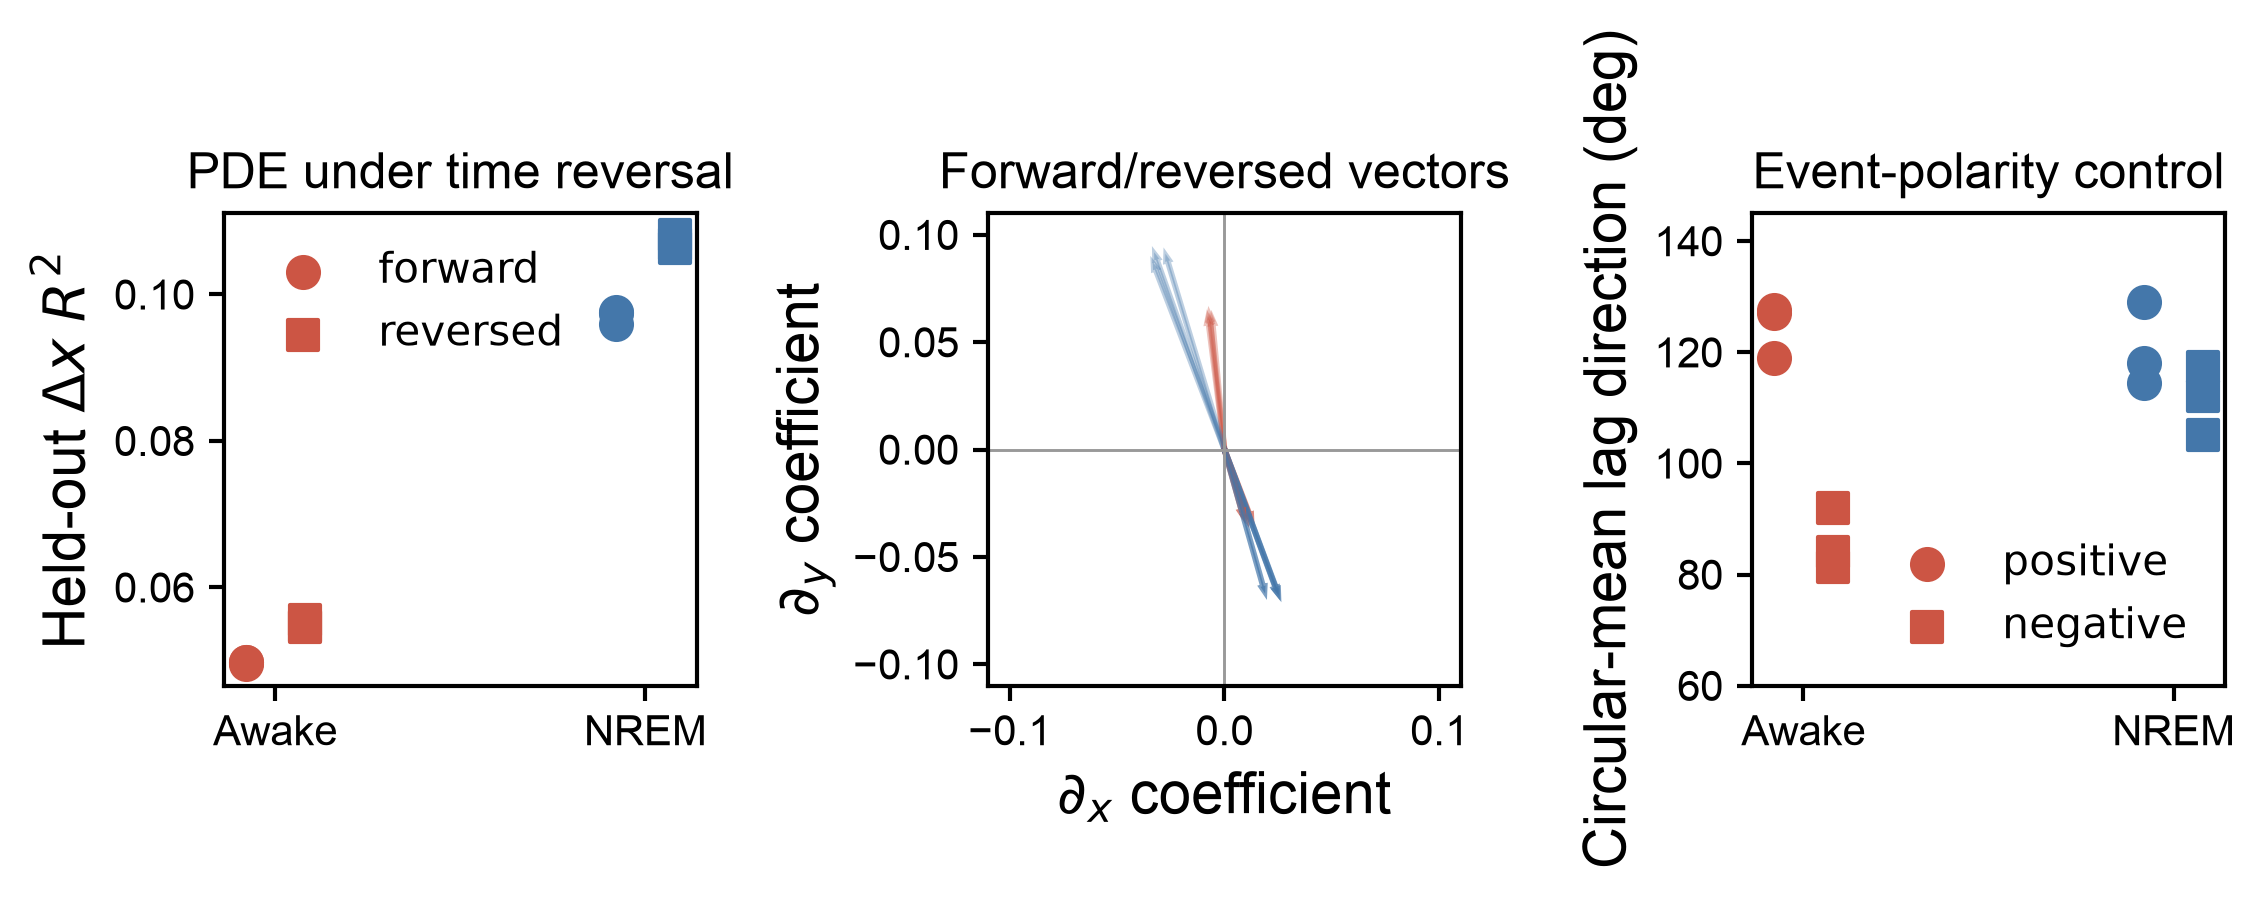

In [7]:
fig, axes = get_fig(RN=1, CN=3, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
ax = next(ax_loader)
for direction, runs, marker, offset in [('forward', forward_runs, 'o', -.08), ('reversed', reverse_runs, 's', .08)]:
    tables = []
    for run in runs:
        table = pd.read_csv(PDE / run / 'model_summary.csv'); table['run'] = run; tables.append(table)
    table = pd.concat(tables)
    for index, state in enumerate(['Awake', 'NREM']):
        values = table[(table.state == state) & (table.model == 'local_advection_diffusion')].dx_r2_flat
        ax.scatter(np.full(len(values), index + offset), values, marker=marker, s=55, color=colors[state], label=direction if index == 0 else None)
ax.set_xticks([0, 1], ['Awake', 'NREM'])
ax.set(ylabel=r'Held-out $\Delta x$ $R^2$', title='PDE under time reversal')
ax.legend(frameon=False)
ax = next(ax_loader)
for direction, runs, alpha in [('forward', forward_runs, .7), ('reversed', reverse_runs, .35)]:
    for run in runs:
        c = pd.read_csv(PDE / run / 'coefficients.csv')
        for state in ['Awake', 'NREM']:
            part = c[(c.state == state) & (c.model == 'local_advection_diffusion')].set_index('term')
            x, y = part.loc['gradient_x'].coefficient_per_frame, part.loc['gradient_y'].coefficient_per_frame
            ax.arrow(0, 0, x, y, color=colors[state], alpha=alpha, width=.0008, length_includes_head=True)
ax.axhline(0, color='0.6', lw=.7); ax.axvline(0, color='0.6', lw=.7)
ax.set(xlabel=r'$\partial_x$ coefficient', ylabel=r'$\partial_y$ coefficient', title='Forward/reversed vectors', xlim=(-.11, .11), ylim=(-.11, .11))
ax.set_aspect('equal')
ax = next(ax_loader)
positive = ['initial', 'seed_20261010', 'seed_20261011']
negative = ['negative_initial', 'negative_seed_20261010', 'negative_seed_20261011']
for polarity, runs, marker, offset in [('positive', positive, 'o', -.08), ('negative', negative, 's', .08)]:
    for index, state in enumerate(['Awake', 'NREM']):
        angles = []
        for run in runs:
            d = pd.read_csv(EVENTS / run / 'event_plane_fits.csv')
            a = d[d.state == state].angle_radians.dropna().to_numpy()
            angles.append(np.degrees(np.angle(np.mean(np.exp(1j*a)))))
        ax.scatter(np.full(3, index + offset), angles, marker=marker, s=55, color=colors[state], label=polarity if index == 0 else None)
ax.set_xticks([0, 1], ['Awake', 'NREM'])
ax.set(ylabel='Circular-mean lag direction (deg)', title='Event-polarity control', ylim=(60, 145))
ax.legend(frameon=False)
fig.savefig(OUT / 'spatial_direction_controls.png', transparent=True)
fig.savefig(OUT / 'spatial_direction_controls.svg', transparent=True)
fig.savefig(OUT / 'spatial_direction_controls.pdf', transparent=True)
plt.show()

Time reversal does not destroy spatial predictability: reversed advection-diffusion R² is higher than forward in both states, and the fitted derivative vector approximately reverses direction. The PDE therefore describes robust spatiotemporal covariance but supplies no physical time arrow.

Negative events also show significant spatial lag planes. NREM trough directions (105°–117°) broadly agree with positive peaks (114°–129°). Awake troughs instead shift to 81°–92° from the positive 119°–128°, demonstrating polarity-dependent propagation geometry. A single fixed scan direction is therefore not a complete description, although acquisition timing remains a plausible contributor.